# Eight-Dimensional Shared-Feature Validation

## Feature extraction, PCA reduction and protected handoff

The selected joint Camelyon–SEER checkpoints produce a 32-dimensional shared representation for each task.

For every upstream seed and task:

1. The selected joint checkpoint extracts 32-dimensional representations.
2. A standard scaler is fitted using training representations only.
3. PCA is fitted using the scaled training representations only.
4. The representation is reduced from 32 to 8 dimensions.
5. The fitted training pipeline transforms the permitted validation splits without refitting.

A matched linear-probe analysis compares the predictive information retained by the original 32-dimensional representation and the reduced 8-dimensional representation.

This notebook covers feature preparation and validation only. It does not implement downstream quantum classification.

Camelyon `ood_test` and SEER `temporal_test` remain locked. No patient identifiers or private feature values are displayed.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

METRICS_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "metrics"
    / "joint_v2"
)

CONFIG_DIR = PROJECT_ROOT / "configs"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

## 1. Shared-feature extraction

Representations are extracted from the selected joint-model checkpoint for each seed.

During extraction:

- The model is placed in evaluation mode.
- Model parameters are frozen.
- No additional training is performed.
- Row order and labels are preserved.
- Patient identifiers are neither loaded nor written.
- Only development splits are processed.

In [2]:
FEATURE_AUDIT_DIR = (
    METRICS_DIR / "feature_extraction"
)

manifest_rows = []

for seed in [42, 123, 2026]:
    for task in ["image", "tabular"]:
        manifest_path = (
            FEATURE_AUDIT_DIR
            / f"seed{seed}_{task}_32d_manifest.json"
        )

        with manifest_path.open(
            "r",
            encoding="utf-8",
        ) as file:
            manifest = json.load(file)

        manifest_rows.append(
            {
                "Seed": seed,
                "Task": (
                    "Camelyon"
                    if task == "image"
                    else "SEER"
                ),
                "Selected epoch":
                    manifest["selected_epoch"],
                "Splits": ", ".join(
                    manifest["development_splits"]
                ),
                "Total extracted rows": sum(
                    split["rows"]
                    for split in manifest[
                        "split_audits"
                    ]
                ),
                "Dimension":
                    manifest["feature_dimension"],
                "Patient IDs in output":
                    manifest["privacy"][
                        "patient_identifiers_in_output"
                    ],
                "Locked test loaded":
                    manifest["test_protection"][
                        "locked_test_loaded"
                    ],
            }
        )

extraction_table = pd.DataFrame(manifest_rows)

extraction_table.style.format(
    {
        "Seed": "{:.0f}",
        "Selected epoch": "{:.0f}",
        "Total extracted rows": "{:,.0f}",
        "Dimension": "{:.0f}",
    }
).hide(axis="index")

Seed,Task,Selected epoch,Splits,Total extracted rows,Dimension,Patient IDs in output,Locked test loaded
42,Camelyon,2,"train, id_val, ood_val","370,900",32,False,False
42,SEER,2,"train, id_val, temporal_val","619,782",32,False,False
123,Camelyon,5,"train, id_val, ood_val","370,900",32,False,False
123,SEER,5,"train, id_val, temporal_val","619,782",32,False,False
2026,Camelyon,2,"train, id_val, ood_val","370,900",32,False,False
2026,SEER,2,"train, id_val, temporal_val","619,782",32,False,False


## 2. Training-only PCA reduction

A separate scaler-and-PCA pipeline is fitted for each task and seed because the image and tabular representations have different distributions.

The reduction procedure is unsupervised:

- Only the complete training split is used.
- Labels are not used during fitting.
- Validation representations are not used during fitting.
- The number of components is fixed at eight before fitting.
- PCA is not refitted on validation data.
- Row order and label hashes are preserved.

In [3]:
PCA_AUDIT_DIR = METRICS_DIR / "pca"

pca_rows = []

for seed in [42, 123, 2026]:
    for task in ["image", "tabular"]:
        audit_path = (
            PCA_AUDIT_DIR
            / f"seed{seed}_{task}_pca_audit.json"
        )

        with audit_path.open(
            "r",
            encoding="utf-8",
        ) as file:
            audit = json.load(file)

        pca_rows.append(
            {
                "Seed": seed,
                "Task": (
                    "Camelyon"
                    if task == "image"
                    else "SEER"
                ),
                "Training rows":
                    audit["fit"]["rows"],
                "Input dimension":
                    audit["source_dimension"],
                "Output dimension":
                    audit["output_dimension"],
                "Explained variance":
                    audit["pca_fit"][
                        "total_explained_variance_ratio"
                    ],
                "Labels used":
                    audit["pca_fit"]["labels_used"],
                "Validation used for fitting":
                    audit["fit"][
                        "validation_features_used"
                    ],
                "Locked test used":
                    audit["fit"][
                        "locked_test_features_used"
                    ],
            }
        )

pca_table = pd.DataFrame(pca_rows)

pca_table.style.format(
    {
        "Seed": "{:.0f}",
        "Training rows": "{:,.0f}",
        "Input dimension": "{:.0f}",
        "Output dimension": "{:.0f}",
        "Explained variance": "{:.4%}",
    }
).hide(axis="index")

Seed,Task,Training rows,Input dimension,Output dimension,Explained variance,Labels used,Validation used for fitting,Locked test used
42,Camelyon,"302,436",32,8,99.9635%,False,False,False
42,SEER,"461,292",32,8,99.9425%,False,False,False
123,Camelyon,"302,436",32,8,99.9737%,False,False,False
123,SEER,"461,292",32,8,99.9728%,False,False,False
2026,Camelyon,"302,436",32,8,99.9468%,False,False,False
2026,SEER,"461,292",32,8,99.9130%,False,False,False


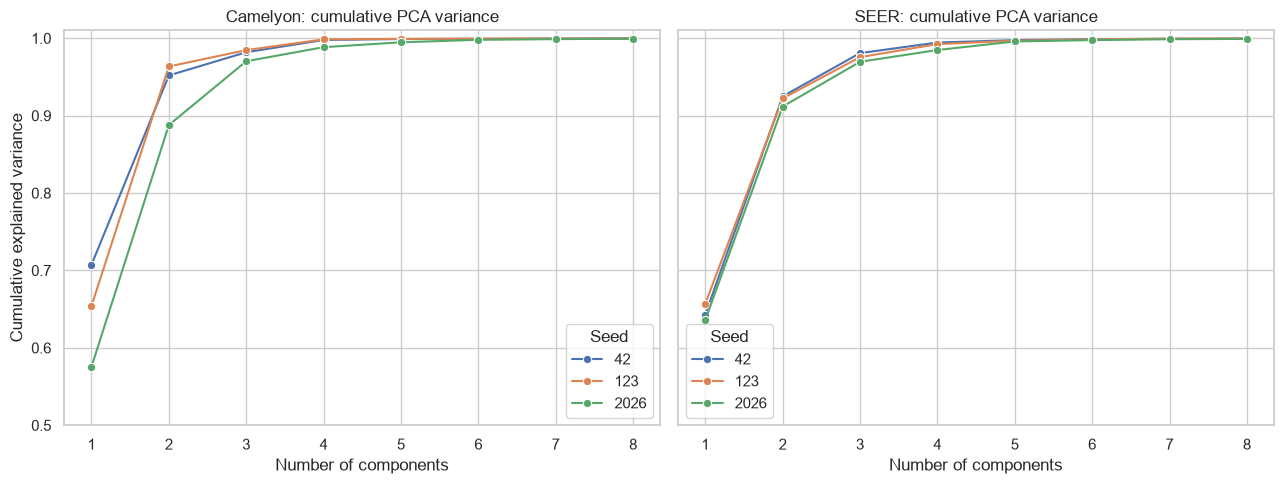

In [4]:
component_rows = []

for seed in [42, 123, 2026]:
    for task in ["image", "tabular"]:
        audit_path = (
            PCA_AUDIT_DIR
            / f"seed{seed}_{task}_pca_audit.json"
        )

        with audit_path.open(
            "r",
            encoding="utf-8",
        ) as file:
            audit = json.load(file)

        cumulative_variance = 0.0

        for component, variance in enumerate(
            audit["pca_fit"][
                "explained_variance_ratio"
            ],
            start=1,
        ):
            cumulative_variance += variance

            component_rows.append(
                {
                    "Seed": str(seed),
                    "Task": (
                        "Camelyon"
                        if task == "image"
                        else "SEER"
                    ),
                    "Component": component,
                    "Cumulative explained variance":
                        cumulative_variance,
                }
            )

component_variance = pd.DataFrame(
    component_rows
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    sharey=True,
)

for axis, task in zip(
    axes,
    ["Camelyon", "SEER"],
):
    sns.lineplot(
        data=component_variance[
            component_variance["Task"] == task
        ],
        x="Component",
        y="Cumulative explained variance",
        hue="Seed",
        marker="o",
        ax=axis,
    )

    axis.set_title(
        f"{task}: cumulative PCA variance"
    )
    axis.set_ylim(0.5, 1.01)
    axis.set_xticks(range(1, 9))
    axis.set_ylabel(
        "Cumulative explained variance"
    )
    axis.set_xlabel("Number of components")

plt.tight_layout()
plt.show()

## 3. Predictive-information retention

High explained variance does not guarantee that class-relevant information is preserved.

A controlled linear-probe comparison therefore evaluates both representations:

- The same unregularised logistic classifier is used.
- The same training and validation rows are used.
- No hyperparameter tuning or threshold selection is performed.
- The only difference is the input representation: 32D or PCA-reduced 8D.
- Locked-test representations are not loaded.

The main comparison uses Camelyon OOD validation and SEER temporal validation.

In [5]:
probe_comparisons = pd.read_csv(
    METRICS_DIR
    / "linear_probe"
    / "joint_v2_linear_probe_comparisons.csv"
)

development_comparisons = probe_comparisons[
    (
        (probe_comparisons["task"] == "image")
        & (
            probe_comparisons["split"]
            == "ood_val"
        )
    )
    |
    (
        (probe_comparisons["task"] == "tabular")
        & (
            probe_comparisons["split"]
            == "temporal_val"
        )
    )
].copy()

probe_rows = []

for task, split, task_name, split_name in [
    (
        "image",
        "ood_val",
        "Camelyon",
        "OOD validation",
    ),
    (
        "tabular",
        "temporal_val",
        "SEER",
        "Temporal validation",
    ),
]:
    rows = development_comparisons[
        (development_comparisons["task"] == task)
        & (
            development_comparisons["split"]
            == split
        )
    ]

    probe_rows.append(
        {
            "Task": task_name,
            "Split": split_name,
            "32D ROC-AUC":
                rows["roc_auc_32d"].mean(),
            "8D ROC-AUC":
                rows["roc_auc_8d"].mean(),
            "AUC change":
                rows[
                    "roc_auc_delta_8d_minus_32d"
                ].mean(),
            "AUC retention":
                rows[
                    "roc_auc_retention_ratio"
                ].mean(),
            "32D accuracy":
                rows["accuracy_32d"].mean(),
            "8D accuracy":
                rows["accuracy_8d"].mean(),
        }
    )

probe_table = pd.DataFrame(probe_rows)

probe_table.style.format(
    {
        "32D ROC-AUC": "{:.6f}",
        "8D ROC-AUC": "{:.6f}",
        "AUC change": "{:+.6f}",
        "AUC retention": "{:.4%}",
        "32D accuracy": "{:.2%}",
        "8D accuracy": "{:.2%}",
    }
).hide(axis="index")

Task,Split,32D ROC-AUC,8D ROC-AUC,AUC change,AUC retention,32D accuracy,8D accuracy
Camelyon,OOD validation,0.980280,0.978598,-0.001683,99.8287%,93.30%,92.95%
SEER,Temporal validation,0.794814,0.794643,-0.000172,99.9784%,76.05%,76.04%


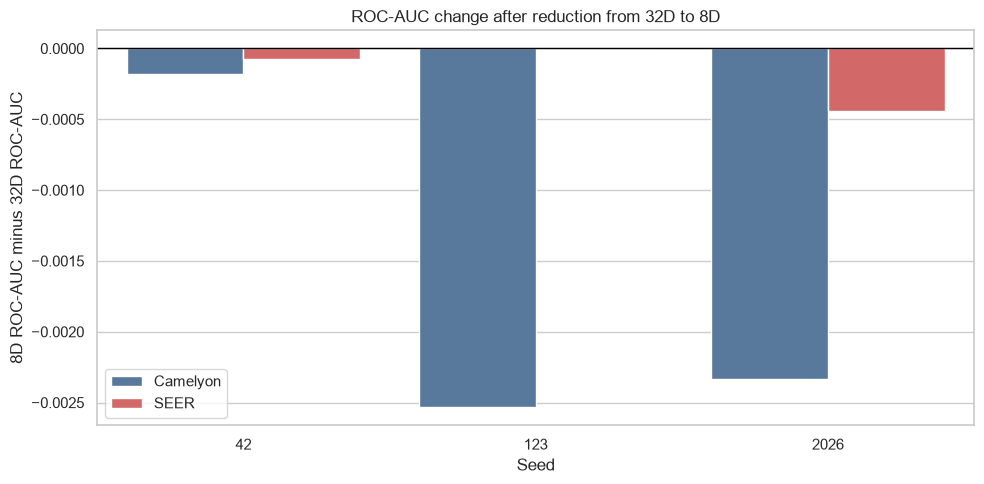

In [6]:
delta_plot = development_comparisons.copy()

delta_plot["Seed"] = delta_plot[
    "seed"
].astype(str)

delta_plot["Task"] = delta_plot[
    "task"
].map(
    {
        "image": "Camelyon",
        "tabular": "SEER",
    }
)

plt.figure(figsize=(10, 5))

axis = sns.barplot(
    data=delta_plot,
    x="Seed",
    y="roc_auc_delta_8d_minus_32d",
    hue="Task",
    palette={
        "Camelyon": "#4C78A8",
        "SEER": "#E45756",
    },
)

axis.axhline(
    0,
    color="black",
    linewidth=1,
)
axis.set_title(
    "ROC-AUC change after reduction from 32D to 8D"
)
axis.set_ylabel("8D ROC-AUC minus 32D ROC-AUC")
axis.set_xlabel("Seed")
axis.legend(title="")

plt.tight_layout()
plt.show()

## 4. Protected feature handoff

The reduced feature archives are private project artifacts and are not committed to GitHub.

Each archive contains:

- `features`: an N × 8 `float32` matrix.
- `labels`: an N-element binary `uint8` vector.

The archives contain no patient identifiers. Public audit files record row counts, dimensions, class counts, hashes and privacy checks without exposing individual feature values or labels.

The development handoff is transferred only to an authorised collaborator through an encrypted archive. The Camelyon OOD test and SEER temporal test are not included.

In [7]:
with (
    CONFIG_DIR / "joint_v2_pca.json"
).open("r", encoding="utf-8") as file:
    pca_config = json.load(file)

handoff_rows = []

for task, task_config in pca_config[
    "tasks"
].items():
    development_splits = task_config[
        "development_transform_splits"
    ]

    handoff_rows.append(
        {
            "Task": (
                "Camelyon"
                if task == "image"
                else "SEER"
            ),
            "Seeds": ", ".join(
                str(seed)
                for seed in pca_config[
                    "random_seeds"
                ]
            ),
            "Included splits": ", ".join(
                development_splits
            ),
            "Development archives": (
                len(pca_config["random_seeds"])
                * len(development_splits)
            ),
            "Feature dimension":
                pca_config["output_dimension"],
            "Archive arrays":
                "features, labels",
            "Committed to GitHub": False,
            "Locked test included": False,
        }
    )

handoff_table = pd.DataFrame(handoff_rows)

handoff_table.style.format(
    {
        "Development archives": "{:.0f}",
        "Feature dimension": "{:.0f}",
    }
).hide(axis="index")

Task,Seeds,Included splits,Development archives,Feature dimension,Archive arrays,Committed to GitHub,Locked test included
Camelyon,"42, 123, 2026","train, id_val, ood_val",9,8,"features, labels",False,False
SEER,"42, 123, 2026","train, id_val, temporal_val",9,8,"features, labels",False,False


## 5. Feature-validation conclusion

The selected joint checkpoints successfully produced 32-dimensional shared representations for all permitted development splits and all three seeds.

Six independent training-only scaler-and-PCA pipelines were fitted:

- Three for Camelyon.
- Three for SEER.

The resulting eight-dimensional representations retained more than 99.91% of total variance in every pipeline.

The controlled linear-probe comparison showed:

- **Camelyon OOD ROC-AUC retention:** 99.83%
- **SEER temporal ROC-AUC retention:** 99.98%

The reduction therefore caused only a very small loss of predictive discrimination while reducing the representation size from 32 to 8 dimensions.

The development archives preserve row order and label hashes, contain no patient identifiers and are excluded from Git. Only aggregate audit records are committed publicly.

This completes the current contributor’s development-stage feature preparation and validation. Final locked-test representations must only be created after the downstream procedure and model states are frozen. The existing scaler and PCA states must then transform the locked splits without refitting.